# Auto-Tuning Gray-Scott Using Julia

# 1. Setup

The setup is the same as in the KernelAbstractions tutorial. The cells below activate the project environment, install and load the packages, and select the backend; first set `DEV` below to match your hardware.

In [1]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :Metal

:Metal

In [2]:
using Pkg
Pkg.activate(joinpath(@__DIR__))

  Activating project at `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks`


In [3]:
Pkg.add(["BenchmarkTools", "ProgressMeter", "Plots", "ColorTypes", "KernelAbstractions", "PythonCall", "JSON", String(DEV)])
Pkg.develop(path="/Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl")

     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`


In [4]:
using BenchmarkTools, ProgressMeter, Plots, ColorTypes, KernelAbstractions, KernelTuner

    CondaPkg Found dependencies: /Users/fjwillemsen/.julia/packages/CondaPkg/Pc7ZA/CondaPkg.toml
    CondaPkg Found dev dependencies: /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl/CondaPkg.toml
    CondaPkg Found dependencies: /Users/fjwillemsen/.julia/packages/PythonCall/trYos/CondaPkg.toml
    CondaPkg Initialising pixi
             │ /Users/fjwillemsen/.julia/artifacts/2d933917be1d230d096513e1ae50dd7ad28a92e0/bin/pixi
             │ init
             │ --format pixi
             └ /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/.CondaPkg
✔ Created /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/.CondaPkg/pixi.toml
    CondaPkg Wrote /Users/fjwillemsen/University/Research/Projects/Bayesian

In [5]:
Pkg.status()

Status `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [3da002f7] ColorTypes v0.12.5
  [7073ff75] IJulia v1.34.4
  [682c06a0] JSON v1.13.4
  [63c18a36] KernelAbstractions v0.10.4
  [d8e2316b] KernelTuner v1.1.0 `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl`
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [6099a3de] PythonCall v0.9.37


In [6]:
if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

MetalBackend()

In [7]:
# Define a lightweight text wrapper class to get live stdout to the cell
using PythonCall
sys = pyimport("sys")
@pyexec """
class JuliaTextStdout:
    def __init__(self, jl_print):
        self.jl_print = jl_print
    def write(self, string):
        if string:
            self.jl_print(string)
        return len(string)
    def flush(self):
        pass
""" => JuliaTextStdout
sys.stdout = JuliaTextStdout(print)

# Define a function to get the source of a cell by tag
using JSON
function get_cell_by_tag(tag_name)
    notebook = JSON.parsefile("gray-scott.ipynb")
    cell_idx = findfirst(notebook["cells"]) do cell
        tags = get(get(cell, "metadata", Dict()), "tags", [])
        return tag_name in tags
    end
    if isnothing(cell_idx)
        error("No cell found with tag: $tag_name")
    end
    source = notebook["cells"][cell_idx]["source"]
    return join(source)
end

get_cell_by_tag (generic function with 1 method)

# 2. The Gray-Scott Reaction-Diffusion Model

The Gray-Scott Reaction-Diffusion model is a mathematical model used to describe how two interacting substances, typically denoted as $U$ and $V$, evolve over time in a spatial domain. This model captures the combined effects of chemical reactions and diffusion, leading to complex pattern formations such as spots, stripes, and waves, which resemble natural phenomena like animal skin patterns or chemical reactions in a petri dish. 

## The Kernel

This kernel is a relatively simple one; for more information on this implementation see [the KernelAbstractions tutorial](). 


In [8]:
using KernelAbstractions

@kernel function gs_gpu_kernel!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise)
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds U[x, y]
        v = @inbounds V[x, y]

        ΔU = my_laplacian(U, x, y, dx)
        ΔV = my_laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        newU = u + DU * dt
        newV = v + DV * dt

        @inbounds Uout[x, y] = newU
        @inbounds Vout[x, y] = newV
    end
end

gs_gpu_kernel! (generic function with 4 methods)

The version we will actually use is a more advanced implementation that gives each work item a **`P` × `Q`** tile of the grid (`P` along `y`, `Q` along `x`; not the PDE parameters `F` or `k`), and uses two helper functions within the kernel to implement this. The kernel also receives the workgroup size `BX` × `BY` as compile-time parameters: Kernel Tuner passes *every* tunable parameter to a Julia kernel as a `Val` argument, in the order they are defined, so the signature needs a slot for each of them (even though the workgroup size itself is set at launch).

In [9]:
using KernelAbstractions

# Fill per-work-item halo cache tile[q, p] = A[x1+q-2, y1+p-2] (out-of-bounds → zero).
# tile is `@private Float32 (Q + 2, P + 2)` — compile-time size from kernel parameters P, Q.
@inline function load_tile!(tile, A, x1, y1, nx, ny, ::Val{P}, ::Val{Q}) where {P, Q}
    @inbounds for q in 1:(Q + 2), p in 1:(P + 2)
        x = x1 + q - 2
        y = y1 + p - 2
        if 1 <= x <= nx && 1 <= y <= ny
            tile[q, p] = A[x, y]
        else
            tile[q, p] = zero(eltype(A))
        end
    end
    return
end

# Laplacian at tile indices (q, p) in 1:Q, 1:P — same 5-point formula as the CPU reference.
@inline function laplacian_tile(tile, q, p, dx)
    u = tile[q + 1, p + 1]
    @inbounds ux_m = tile[q, p + 1]
    @inbounds ux_p = tile[q + 2, p + 1]
    @inbounds uy_m = tile[q + 1, p]
    @inbounds uy_p = tile[q + 1, p + 2]
    ((ux_m - 2 * u + ux_p) + (uy_m - 2 * u + uy_p)) / dx
end

@kernel function gs_gpu_kernel_tuned!(Uout, Vout, @Const(U), @Const(V),
        D_u, D_v, F, k, dt, dx, nx, ny, noise, ::Val{P}, ::Val{Q}, ::Val{BX}, ::Val{BY}) where {P, Q, BX, BY}
    # Section 1: get indices
    i, j = @index(Global, NTuple)
    x1 = (i - 1) * Q + 1
    y1 = (j - 1) * P + 1

    # Section 2: allocate register memory and get data
    tileU = @private Float32 (Q + 2, P + 2)
    tileV = @private Float32 (Q + 2, P + 2)
    stepU = @private Float32 (Q, P)
    stepV = @private Float32 (Q, P)

    if (x1 < nx) && (x1 + Q > 2)
        load_tile!(tileU, U, x1, y1, nx, ny, Val(P), Val(Q))
        load_tile!(tileV, V, x1, y1, nx, ny, Val(P), Val(Q))

        # Section 3: calculate Laplacians (values → private step tile)
        for q in 1:Q, p in 1:P
            if (1 < x1 + q - 1 < nx) && (1 <  y1 + p - 1 < ny)
                u = tileU[q + 1, p + 1]
                v = tileV[q + 1, p + 1]
                ΔU = laplacian_tile(tileU, q, p, dx)
                ΔV = laplacian_tile(tileV, q, p, dx)
                UVV = u * v * v
                Nr = noise == 0 ? zero(u) : noise * randn(Float32)
                DU = D_u * ΔU - UVV + F * (1 - u) + Nr
                DV = D_v * ΔV + UVV - (F + k) * v
                stepU[q, p] = u + DU * dt
                stepV[q, p] = v + DV * dt
            end
        end

        # Section 4: global writes
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                @inbounds Uout[x, y] = stepU[q, p]
                @inbounds Vout[x, y] = stepV[q, p]
            end
        end
    end
end

gs_gpu_kernel_tuned! (generic function with 4 methods)

Now that we have our kernel source code in a file, it might be nice to see what it actually does (don't worry about the implementation details of the cell below). 

In [ ]:
function simulate_gs_tuned(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        P = 4, Q = 1,
                        workgroup = (16, 16),
                        init_multi = 0.5,
                        noise = 0.0f0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    # Same host init as the reference CPU implementation
    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    # (5) specialize @kernel for Backend
    kernel = gs_gpu_kernel_tuned!(Backend, workgroup)
    ndrange = (cld(n, Q), cld(n, P))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model (tunable)", xlabel="X", ylabel="Y")

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            # (5) launch — read U/V, write Uout/Vout; swap buffers each step
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise,
                Val(P), Val(Q), Val(workgroup[1]), Val(workgroup[2]), ndrange = ndrange)
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        # (5) device → host + synchronize before plotting
        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.copyto!(Backend, V, readV)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model (tuned)")
    end
    gif(anim, "gs_tuned.gif"; fps=10)
end

simulate_gs_tuned (generic function with 3 methods)

Let's see our Gray-Scott Model in action:

Progress: 100%|█████████████████████████████████████████| Time: 0:00:21
[ Info: Saved animation to /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_tuned.gif


 23.471429 seconds (415.78 M allocations: 13.952 GiB, 5.27% gc time, 29.07% compilation time: 26% of which was recompilation)


Plots.AnimatedGif("/Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_tuned.gif")
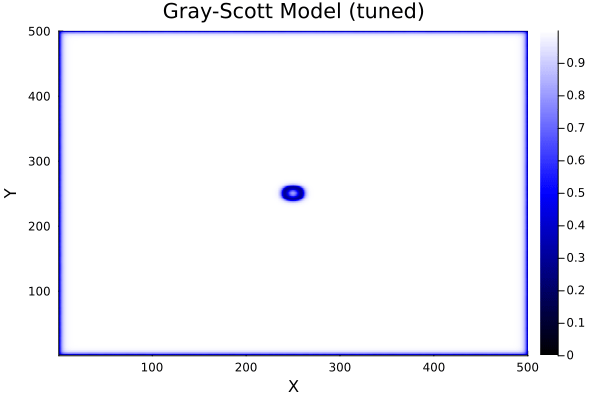

In [11]:
# @time simulate_gs_tuned(500, 10000)

# Autotuning the Kernel

Now that we have our kernel source code in a file, we can get started on the tuning script! We start by generating some input data that we will use to benchmark our GPU kernel.

In [12]:
# parameters
n = 500
init_multi = 0.5

U = Float32.(rand(0.0:0.001:0.1, n, n))
V = zeros(Float32, n, n)

n_mid = div(n, 2)
U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
KernelAbstractions.copyto!(Backend, U1, U)
KernelAbstractions.copyto!(Backend, V1, V)
KernelAbstractions.copyto!(Backend, U2, U)
KernelAbstractions.copyto!(Backend, V2, V)

500×500 MtlMatrix{Float32, Metal.SharedStorage}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0 

In [13]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
result = KernelTuner.run_kernel(
    "gs_gpu_kernel_tuned!",
    get_cell_by_tag("gs_gpu_kernel_tuned"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    params=[
        ("P", 4),
        ("Q", 1),
        ("block_size_x", 16),
        ("block_size_y", 16),
    ],
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia"
)
display(result)

Using: Apple M5 Pro


13-element Vector{Any}:
    MtlArray(Float32[0.035 0.059 … 0.077 0.021; 0.068 0.10262 … 0.093955 0.071; … ; 0.042 0.0662 … 0.083165 0.033; 0.088 0.027 … 0.064 0.049])
    MtlArray(Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])
    MtlArray(Float32[0.035 0.059 … 0.077 0.021; 0.068 0.084 … 0.047 0.071; … ; 0.042 0.0 … 0.065 0.033; 0.088 0.027 … 0.064 0.049])
    MtlArray(Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])
   0.16f0
   0.08f0
   0.035f0
   0.06f0
   1.0f0
   1.0f0
 500
 500
   0.0f0

In [ ]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
]

results, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tuned!",
    get_cell_by_tag("gs_gpu_kernel_tuned"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results)

Using: Apple M5 Pro
Searchspace has 272 configurations after restrictions.
P=1, Q=1, block_size_x=8, block_size_y=4, time=0.354ms
P=1, Q=1, block_size_x=8, block_size_y=8, time=0.448ms
P=1, Q=1, block_size_x=8, block_size_y=16, time=0.356ms
P=1, Q=1, block_size_x=16, block_size_y=2, time=0.383ms
P=1, Q=1, block_size_x=16, block_size_y=4, time=0.561ms
P=1, Q=1, block_size_x=16, block_size_y=8, time=0.582ms
P=1, Q=1, block_size_x=16, block_size_y=16, time=0.609ms
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.577ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.511ms
P=1, Q=1, block_size_x=32, block_size_y=4, time=0.494ms
P=1, Q=1, block_size_x=32, block_size_y=8, time=0.413ms
P=1, Q=1, block_size_x=32, block_size_y=16, time=0.419ms
P=1, Q=1, block_size_x=64, block_size_y=1, time=0.485ms
P=1, Q=1, block_size_x=64, block_size_y=2, time=0.330ms
P=1, Q=1, block_size_x=64, block_size_y=4, time=0.377ms
P=1, Q=1, block_size_x=64, block_size_y=8, time=0.422ms
P=1, Q=1, block_size_x=64, bl

272-element Vector{Dict}:
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 15:12:51.867211+00:00", "time" => 0.35413882299751537, "block_size_x" => 8.0, "times" => Any[0.312, 0.28929232331478594, 0.3002499699443579, 0.27808402815201877, 0.30133264662957193, 0.3034996466295719, 0.652374323314786], "compile_time" => 6.112542003393173, "verification_time" => 0, "framework_time" => 1.6114719610939217, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 15:12:52.045598+00:00", "time" => 0.44828472524446744, "block_size_x" => 8.0, "times" => Any[0.586334, 0.605833, 0.612833, 0.6040826466295719, 0.295875, 0.286917323314786, 0.28416738152244686], "compile_time" => 6.0501249972730875, "verification_time" => 0, "framework_time" => 1.6114719610939217, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 15:12:52.212775+00:00", "time" => 0.35631949467345575, "block_size_x" => 8.0, 

In [ ]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [8, 16, 32, 64]),      # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),     # workgroup size along y
]
# keep workgroups between one SIMD-group (32) and the hardware maximum (1024 work-items)
restrictions = ["32 <= block_size_x * block_size_y <= 1024"]

results, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tuned!",
    get_cell_by_tag("gs_gpu_kernel_tuned"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    restrictions=restrictions,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results)